In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [35]:
df.shape

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [36]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [37]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = df[features].copy()
y = df["Survived"].to_numpy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 7)
Target shape: (891,)


In [38]:
np.random.seed(100)

indices = np.random.permutation(len(X))

train_size = int(0.6 * len(X))
val_size = int(0.2 * len(X))

train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

X_train = X.iloc[train_indices].copy()
X_val = X.iloc[val_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (534, 7) (534,)
Validation set: (178, 7) (178,)
Testing set: (179, 7) (179,)


In [39]:
print(X_train.isnull().sum())

Pclass       0
Sex          0
Age         97
SibSp        0
Parch        0
Fare         0
Embarked     2
dtype: int64


In [40]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

for data in [X_train, X_val, X_test]:
    data["Age"] = data["Age"].fillna(age_median)
    data["Embarked"] = data["Embarked"].fillna(embarked_mode)

In [41]:
embarked_modes = X_train["Embarked"].mode()

print("Mode:")
print(embarked_modes)

Mode:
0    S
Name: Embarked, dtype: str


In [42]:
embarked_mode = X_train["Embarked"].mode()[0]

In [43]:
X_train["Embarked"] = X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"] = X_test["Embarked"].fillna(embarked_mode)

In [44]:
X_train = pd.get_dummies(
    X_train, columns=["Sex", "Embarked"], dtype=int
)

X_val = pd.get_dummies(
    X_val, columns=["Sex", "Embarked"], dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=["Sex", "Embarked"], dtype=int
)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

Standardizing the numerical columns using:
z=(x-mu)/sigma

In [45]:
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

means = X_train[numeric_features].mean()
stds = X_train[numeric_features].std(ddof=0)

stds = stds.replace(0, 1)

for data in [X_train, X_val, X_test]:
    data[numeric_features] = (
        data[numeric_features] - means
    ) / stds

In [46]:
X_train = X_train.to_numpy(dtype=float)
X_val = X_val.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (534, 10)
X_test: (179, 10)
y_train: (534,)
y_test: (179,)


In [47]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [48]:
test_values = np.array([-10, -2, 0, 2, 10])

print(sigmoid(test_values))

[4.53978687e-05 1.19202922e-01 5.00000000e-01 8.80797078e-01
 9.99954602e-01]


In [49]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    return loss

In [50]:
y_example = np.array([1, 0, 1, 0])

predictions_good = np.array([0.9, 0.1, 0.8, 0.2])
predictions_bad = np.array([0.1, 0.9, 0.2, 0.8])

print("Good predictions:", compute_loss(y_example, predictions_good))
print("Bad predictions:", compute_loss(y_example, predictions_bad))

Good predictions: 0.164252033486018
Bad predictions: 1.9560115027140732


In [51]:
def train_logistic_regression(
    X, y, alpha, lam=0.0, iterations=1000
):
    m, n = X.shape

    w = np.zeros(n)
    b = 0.0
    losses = []

    for i in range(iterations):
       
        z = X @ w + b
        y_pred = sigmoid(z)
        
        errors = y_pred - y

        dw = (X.T @ errors) / m + (lam / m) * w
        db = np.mean(errors)

        w -= alpha * dw
        b -= alpha * db

        y_pred = sigmoid(X @ w + b)
        loss = compute_loss(y, y_pred)
        loss += (lam / (2 * m)) * np.sum(w ** 2)

        losses.append(loss)

    return w, b, losses

In [52]:
alphas = [0.001, 0.01, 0.1, 0.5]
iterations = 1000

results = {}

for alpha in alphas:
    w, b, losses = train_logistic_regression(
        X_train,
        y_train,
        alpha=alpha,
        iterations=iterations
    )

    results[alpha] = {
        "w": w,
        "b": b,
        "losses": losses
    }

    print(f"alpha={alpha}: final loss={losses[-1]:.4f}")

alpha=0.001: final loss=0.6149
alpha=0.01: final loss=0.4848
alpha=0.1: final loss=0.4532
alpha=0.5: final loss=0.4532


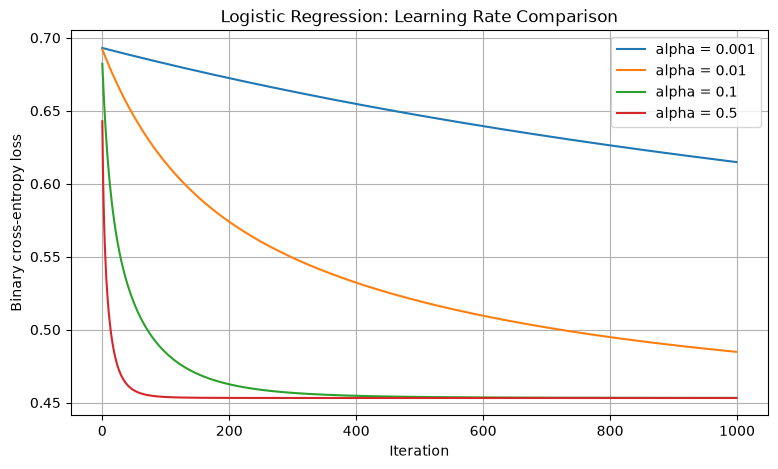

In [53]:
plt.figure(figsize=(9, 5))

for alpha, result in results.items():
    plt.plot(
        result["losses"],
        label=f"alpha = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Binary cross-entropy loss")
plt.title("Logistic Regression: Learning Rate Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
lambdas = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0]

alpha = 0.1
iterations = 1000

regularization_results = {}

for lam in lambdas:
    w, b, losses = train_logistic_regression(
        X_train,
        y_train,
        alpha=alpha,
        lam=lam,
        iterations=iterations
    )

    # Training predictions
    train_prob = sigmoid(X_train @ w + b)
    train_pred = (train_prob >= 0.5).astype(int)

    # Validation predictions
    val_prob = sigmoid(X_val @ w + b)
    val_pred = (val_prob >= 0.5).astype(int)

    # Unregularized BCE on both datasets
    train_bce = compute_loss(y_train, train_prob)
    val_bce = compute_loss(y_val, val_prob)

    # Accuracy on both datasets
    train_accuracy = np.mean(train_pred == y_train)
    val_accuracy = np.mean(val_pred == y_val)

    regularization_results[lam] = {
        "w": w,
        "b": b,
        "losses": losses,
        "train_bce": train_bce,
        "val_bce": val_bce,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy
    }

    print(
        f"lambda={lam:<6} "
        f"Train BCE={train_bce:.4f} | "
        f"Val BCE={val_bce:.4f} | "
        f"Train Acc={train_accuracy:.2%} | "
        f"Val Acc={val_accuracy:.2%}"
    )

lambda=0.0    Train BCE=0.4532 | Val BCE=0.4137 | Train Acc=78.65% | Val Acc=82.58%
lambda=0.001  Train BCE=0.4532 | Val BCE=0.4137 | Train Acc=78.65% | Val Acc=82.58%
lambda=0.01   Train BCE=0.4532 | Val BCE=0.4137 | Train Acc=78.65% | Val Acc=82.58%
lambda=0.1    Train BCE=0.4532 | Val BCE=0.4137 | Train Acc=78.65% | Val Acc=82.58%
lambda=1.0    Train BCE=0.4535 | Val BCE=0.4141 | Train Acc=78.84% | Val Acc=82.58%
lambda=10.0   Train BCE=0.4615 | Val BCE=0.4231 | Train Acc=80.52% | Val Acc=82.02%


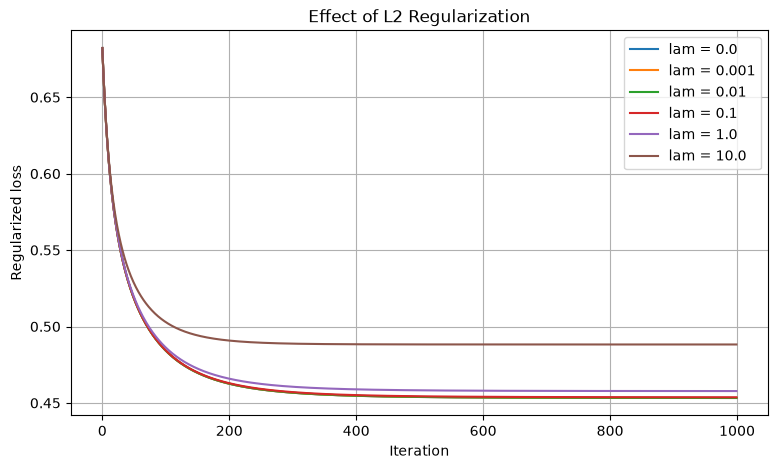

In [55]:
plt.figure(figsize=(9,5))

for lam, result in regularization_results.items():
    plt.plot(
        result["losses"],
        label=f"lam = {lam}"
    )

plt.xlabel("Iteration")
plt.ylabel("Regularized loss")
plt.title("Effect of L2 Regularization")
plt.legend()
plt.grid(True)
plt.show()

In [56]:
chosen_lam = min(
    regularization_results,
    key=lambda lam: regularization_results[lam]["val_bce"]
)

chosen_result = regularization_results[chosen_lam]

print(f"Chosen lambda: {chosen_lam}")
print(f"Training BCE: {chosen_result['train_bce']:.4f}")
print(f"Validation BCE: {chosen_result['val_bce']:.4f}")
print(f"Training accuracy: {chosen_result['train_accuracy']:.2%}")
print(f"Validation accuracy: {chosen_result['val_accuracy']:.2%}")  

Chosen lambda: 0.0
Training BCE: 0.4532
Validation BCE: 0.4137
Training accuracy: 78.65%
Validation accuracy: 82.58%


In [57]:
w = chosen_result["w"]
b = chosen_result["b"]

# Final predictions on the untouched test set
y_test_prob = sigmoid(X_test @ w + b)
y_test_pred = (y_test_prob >= 0.5).astype(int)

test_bce = compute_loss(y_test, y_test_prob)
test_accuracy = np.mean(y_test_pred == y_test)

print(f"Chosen lambda: {chosen_lam}")
print(f"Test BCE: {test_bce:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Chosen lambda: 0.0
Test BCE: 0.4445
Test accuracy: 78.77%


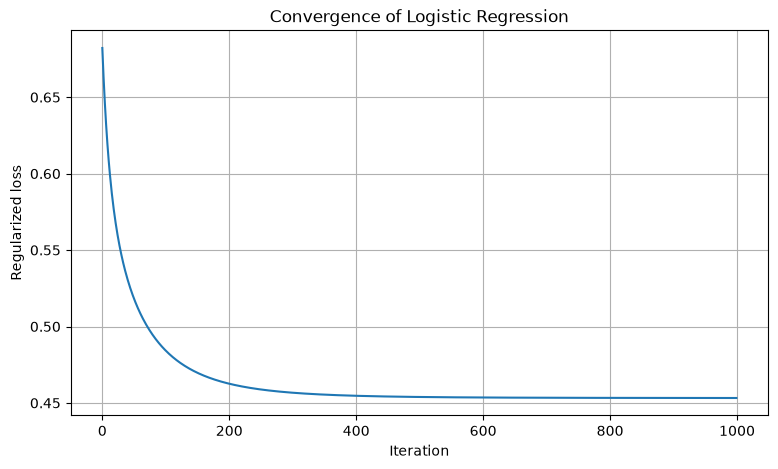

In [58]:
losses = regularization_results[chosen_lam]["losses"]

plt.figure(figsize=(9, 5))
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Regularized loss")
plt.title("Convergence of Logistic Regression")
plt.grid(True)
plt.show()

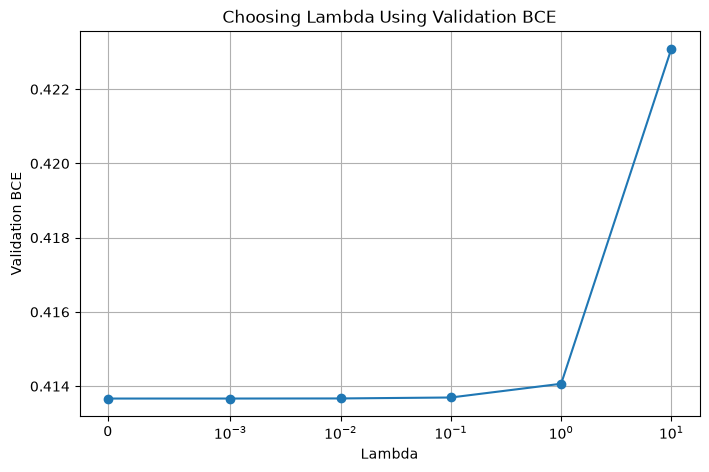

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(regularization_results.keys()),
    [r["val_bce"] for r in regularization_results.values()],
    marker="o"
)

plt.xscale("symlog", linthresh=0.001)
plt.xlabel("Lambda")
plt.ylabel("Validation BCE")
plt.title("Choosing Lambda Using Validation BCE")
plt.grid(True)
plt.show()

In [60]:
y_test_prob = sigmoid(X_test @ w + b)
y_test_pred = (y_test_prob >= 0.5).astype(int)

print("First 10 predicted probabilities:", y_test_prob[:10])
print("First 10 predicted classes:\t", y_test_pred[:10])
print("First 10 actual classes:\t", y_test[:10])

First 10 predicted probabilities: [0.87528473 0.24589802 0.68296868 0.14626848 0.13298636 0.11406701
 0.01083474 0.43964037 0.08890849 0.0781148 ]
First 10 predicted classes:	 [1 0 1 0 0 0 0 0 0 0]
First 10 actual classes:	 [1 0 0 0 0 0 0 1 0 0]


In [61]:
accuracy = np.mean(y_test_pred == y_test)

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

Test accuracy: 0.7877
Test accuracy: 78.77%


In [62]:
tn = np.sum((y_test == 0) & (y_test_pred == 0))
fp = np.sum((y_test == 0) & (y_test_pred == 1))
fn = np.sum((y_test == 1) & (y_test_pred == 0))
tp = np.sum((y_test == 1) & (y_test_pred == 1))

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

print(confusion_matrix)

precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) else 0.0
)

print(f"Precision: {precision:.4f} ({precision:.2%})")
print(f"Recall:    {recall:.4f} ({recall:.2%})")
print(f"F1-score:  {f1_score:.4f}") 

[[94 21]
 [17 47]]
Precision: 0.6912 (69.12%)
Recall:    0.7344 (73.44%)
F1-score:  0.7121


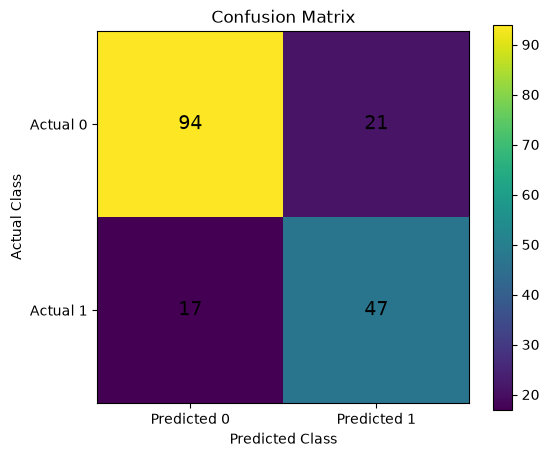

In [63]:
plt.figure(figsize=(6, 5))

plt.imshow(confusion_matrix)
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, confusion_matrix[i, j],
            ha="center", va="center", fontsize=14
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [64]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1_score = 2 * precision * recall / (precision + recall)

print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score:  {f1_score:.4f}")

Precision: 0.6912 (69.12%)
Recall:    0.7344 (73.44%)
F1-score:  0.7121
